FINANCIAL AND PREMIUM CUSTOMER RISK ANALYSIS

Total customers: 10,000
Total dataset columns: 26

CUSTOMER BALANCE DISTRIBUTION


,Balance
count,10000.000000
mean,76485.889288
std,62397.405202
min,0.000000
25%,0.000000
50%,97198.540000
75%,127644.240000
max,250898.090000



ESTIMATED SALARY DISTRIBUTION


,Estimated Salary
count,10000.000000
mean,100090.239881
std,57510.492818
min,11.580000
25%,51002.110000
50%,100193.915000
75%,149388.247500
max,199992.480000



FINANCIAL STATISTICAL MEASURES


,Metric,Balance,Estimated Salary
0,Mean,7.648589e+04,1.000902e+05
1,Median,9.719854e+04,1.001939e+05
2,Standard Deviation,6.239741e+04,5.751049e+04
3,Minimum,0.000000e+00,1.158000e+01
4,25th Percentile,0.000000e+00,5.100211e+04
5,50th Percentile,9.719854e+04,1.001939e+05
6,75th Percentile,1.276442e+05,1.493882e+05
7,Maximum,2.508981e+05,1.999925e+05
8,Total,7.648589e+08,1.000902e+09


... (7 outputs left out)

,activity_status,customers,average_balance,median_balance,average_salary,average_age,average_products,exited_customers,churn_rate,retention_rate
0,Active,812,157863.22,153600.67,99788.04,39.49,1.39,127,15.64,84.36
1,Inactive,784,158133.80,153579.97,100861.77,38.18,1.39,240,30.61,69.39



PREMIUM-RISK SEGMENT RANKING


,premium_risk_segment,customers,average_balance,inactive_customers,exited_customers,average_products,churn_rate,retention_priority_rank
0,Critical Attention - Inactive Single Product,338,157691.08,338,0,1.00,0.00,1
1,High Attention - Inactive Multi Product,206,157445.99,206,0,2.00,0.00,2
3,Monitor - Active High Balance,685,157246.72,0,0,1.36,0.00,3
2,Historical Churn - Exited High Balance,367,159984.65,240,367,1.45,100.00,4
4,Standard Segment,8404,61006.31,4065,1670,1.56,19.87,5



CUSTOMER-LEVEL EXPORTS COMPLETED
All customer records: 10000
Inactive retained high-balance customers: 544
Active high-balance customers: 812
Exited high-balance customers: 367


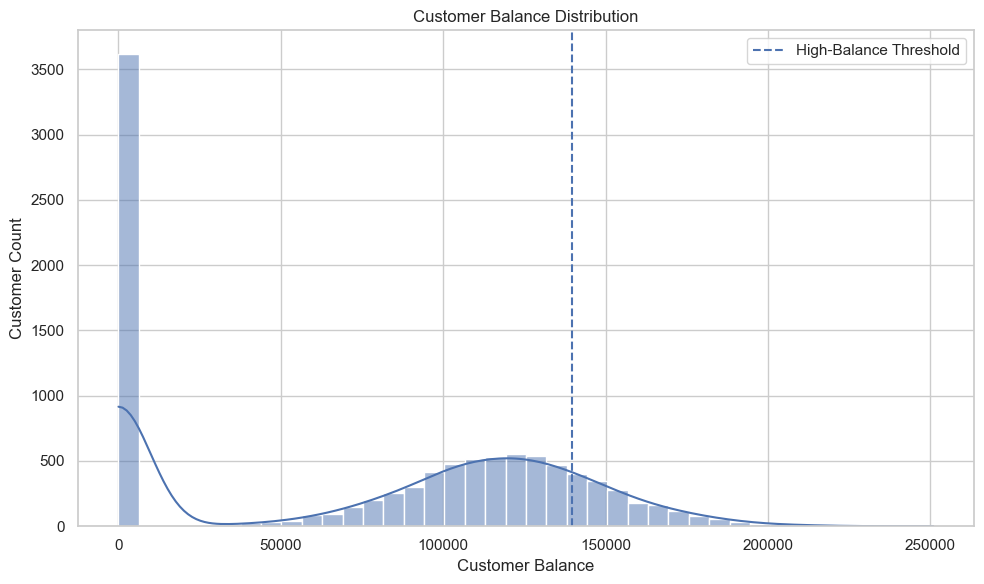

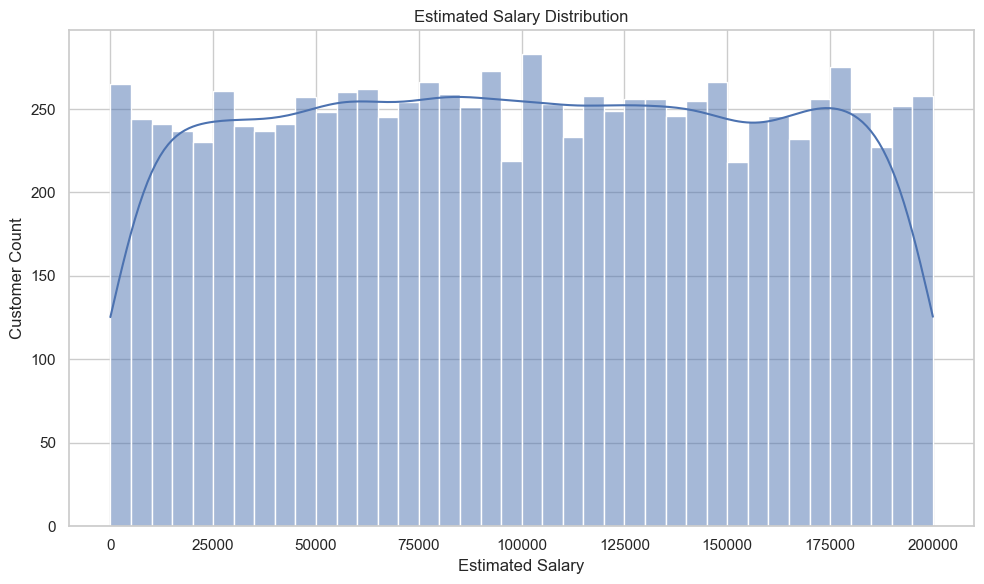

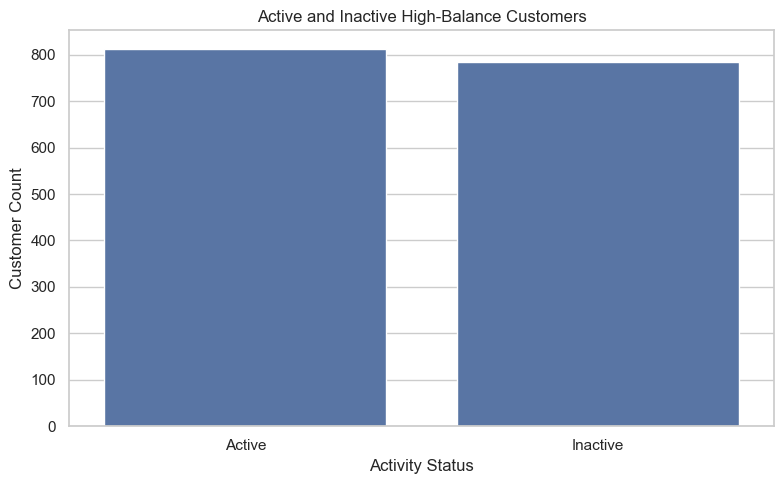

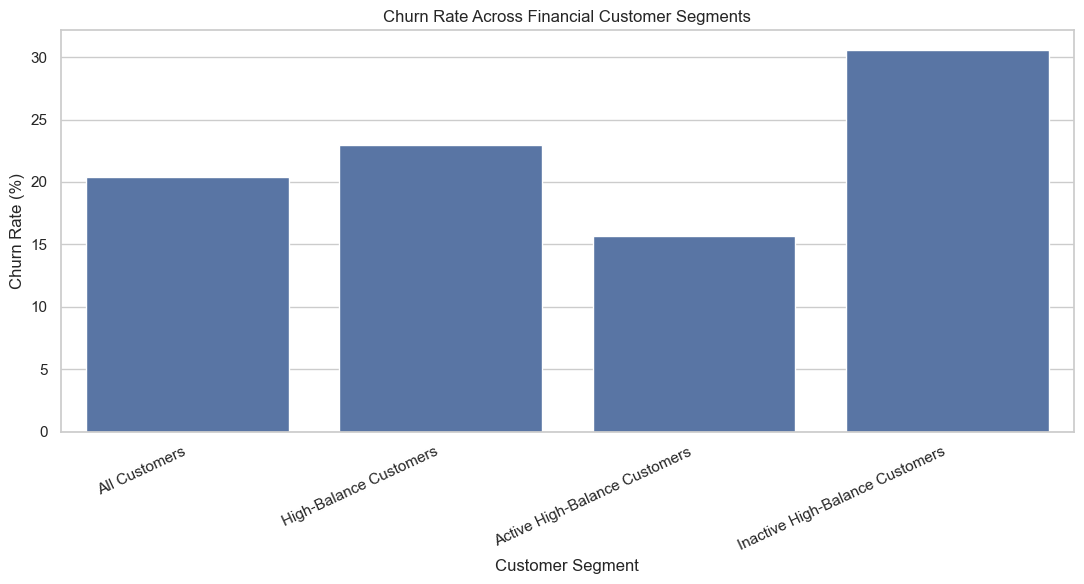

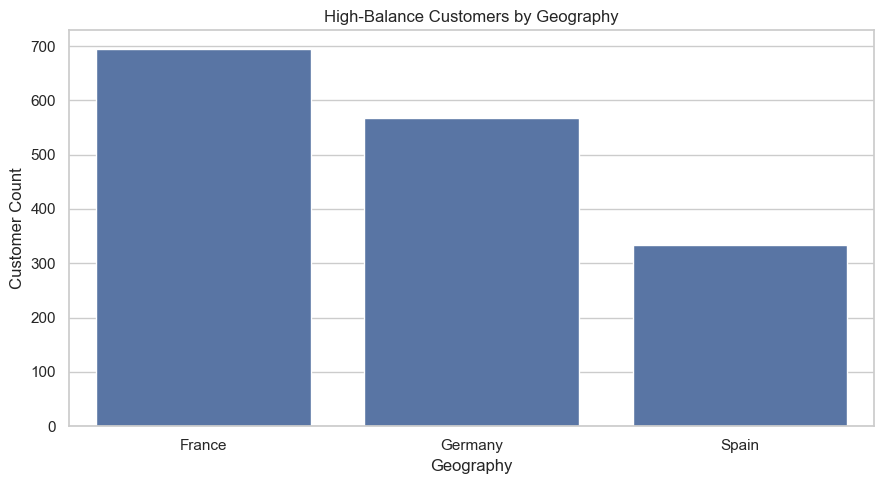

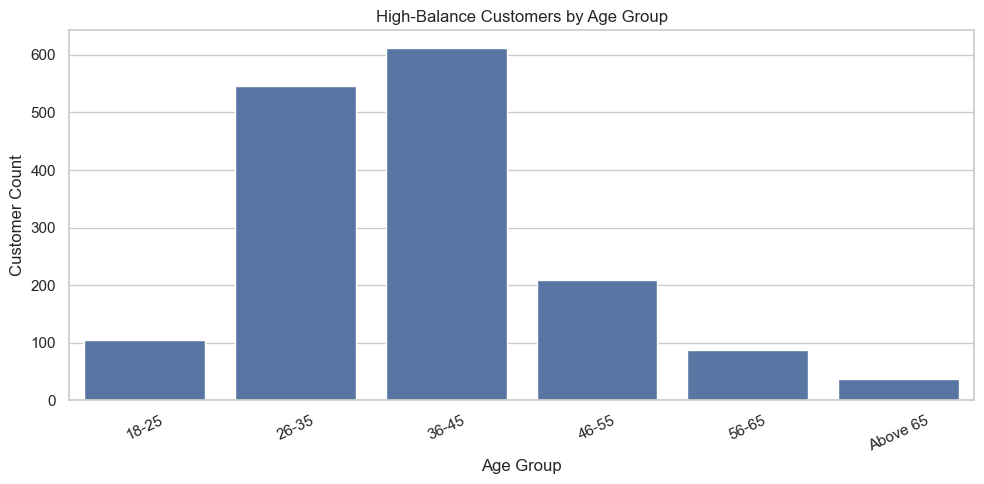

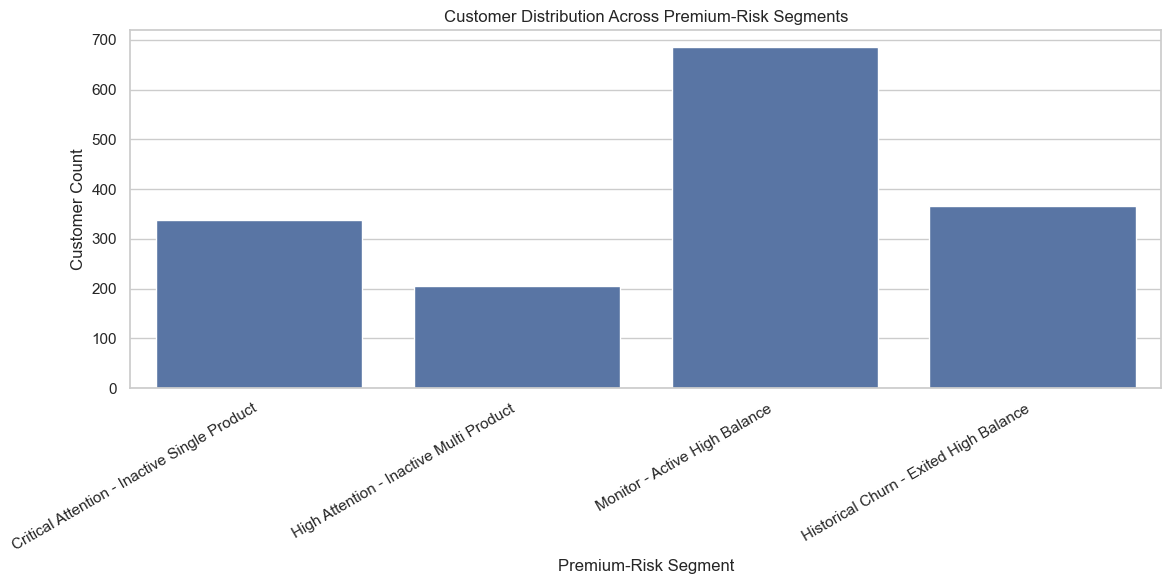


FINANCIAL AND PREMIUM-RISK FINDINGS
FINANCIAL AND PREMIUM CUSTOMER RISK FINDINGS
Total customers analyzed: 10,000
Average balance: 76,485.89
Median balance: 97,198.54
Average estimated salary: 100,090.24
Median estimated salary: 100,193.91
High-balance threshold: 139,512.29
High-balance customers: 1,596
Inactive high-balance customers: 784
Active high-balance customers: 812
Exited high-balance customers: 367
High-Balance Disengagement Rate: 49.12%
High-balance churn rate: 22.99%
Overall churn rate: 20.37%
Inactive retained high-balance customers: 544
Largest high-balance geography: France
Largest high-balance age group: 36-45

RETENTION ATTENTION RECOMMENDATIONS
-----------------------------------------------------------------
1. Review inactive retained high-balance customers for targeted engagement.
2. Review inactive single-product high-balance customers for suitable product education and cross-sell opportunities.
3. Monitor active high-balance customers to maintain their existing 

,Validation,Result,Details
0,Total customer reconciliation,True,"1,596 high-balance + 8,404 other"
1,High-balance activity reconciliation,True,812 active + 784 inactive
2,High-balance churn reconciliation,True,"367 exited + 1,229 retained"
3,High-balance threshold validity,True,"Threshold = 139,512.29"
4,Customer ID uniqueness,True,Customer IDs must be unique
5,Customer-level export reconciliation,True,"10,000 exported / 10,000 total"
6,HBDR percentage validity,True,HBDR = 49.12%



FINANCIAL AND PREMIUM-RISK ANALYSIS COMPLETED

Tables and reports saved to:
C:\Users\hp\Customer Engagement & Product Utilization Analytics for Retention Strategy\outputs\tables\financial_premium_risk

Charts saved to:
C:\Users\hp\Customer Engagement & Product Utilization Analytics for Retention Strategy\outputs\figures\financial_premium_risk

Generated table files:
 - active_high_balance_customers.csv
 - active_inactive_high_balance_comparison.csv
 - balance_distribution.csv
 - customer_level_premium_risk_segments.csv
 - exited_high_balance_customers.csv
 - financial_premium_risk_findings.txt
 - financial_risk_validation_results.csv
 - financial_statistical_measures.csv
 - high_balance_by_age_group.csv
 - high_balance_by_geography.csv
 - high_balance_churn_comparison.csv
 - inactive_retained_high_balance_customers.csv
 - premium_risk_segment_ranking.csv
 - salary_distribution.csv

Generated chart files:
 - balance_distribution.png
 - high_balance_activity_comparison.png
 - high_balan

In [5]:
# Financial Profile, High-Balance Customer and Premium Risk Analytics

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Configure project directories
# ------------------------------------------------------------

PROJECT_PATH = (
    r"C:\Users\hp\Customer Engagement & Product Utilization Analytics for Retention Strategy"
)

INPUT_FILE = os.path.join(
    PROJECT_PATH,
    "data",
    "processed",
    "European_Bank_Cleaned_Analytical.csv"
)

TABLE_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "tables",
    "financial_premium_risk"
)

FIGURE_PATH = os.path.join(
    PROJECT_PATH,
    "outputs",
    "figures",
    "financial_premium_risk"
)

os.makedirs(TABLE_PATH, exist_ok=True)
os.makedirs(FIGURE_PATH, exist_ok=True)

# ------------------------------------------------------------
# Load and validate analytical dataset
# ------------------------------------------------------------

if not os.path.exists(INPUT_FILE):
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_FILE}"
    )

df = pd.read_csv(INPUT_FILE)

def normalize_column_name(column):
    return re.sub(r"[^a-z0-9]", "", str(column).lower())

df.columns = [
    normalize_column_name(col) for col in df.columns
]

required_columns = [
    "customerid",
    "geography",
    "age",
    "balance",
    "estimatedsalary",
    "numofproducts",
    "isactivemember",
    "exited"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

numeric_columns = [
    "age",
    "balance",
    "estimatedsalary",
    "numofproducts",
    "isactivemember",
    "exited"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

if df[numeric_columns].isnull().any().any():
    raise ValueError(
        "Missing or invalid numeric values found."
    )

if df["customerid"].isnull().any():
    raise ValueError("CustomerId contains missing values.")

if df["customerid"].duplicated().any():
    raise ValueError("Duplicate CustomerId values detected.")

if not df["isactivemember"].isin([0, 1]).all():
    raise ValueError("Invalid IsActiveMember values.")

if not df["exited"].isin([0, 1]).all():
    raise ValueError("Invalid Exited values.")

if (df["balance"] < 0).any():
    raise ValueError("Negative balances detected.")

if (df["estimatedsalary"] < 0).any():
    raise ValueError("Negative estimated salaries detected.")

if (df["numofproducts"] < 1).any():
    raise ValueError("Invalid product counts detected.")

print("=" * 75)
print("FINANCIAL AND PREMIUM CUSTOMER RISK ANALYSIS")
print("=" * 75)

print(f"\nTotal customers: {len(df):,}")
print(f"Total dataset columns: {len(df.columns)}")

# ------------------------------------------------------------
# Create customer activity and status categories
# ------------------------------------------------------------

df["activity_status"] = np.where(
    df["isactivemember"] == 1,
    "Active",
    "Inactive"
)

df["customer_status"] = np.where(
    df["exited"] == 1,
    "Exited",
    "Retained"
)

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "Above 65"
    ],
    include_lowest=True
)

# ------------------------------------------------------------
# Analyze customer balance distribution
# ------------------------------------------------------------

balance_distribution = df["balance"].describe()

print("\nCUSTOMER BALANCE DISTRIBUTION")
display(balance_distribution.to_frame("Balance"))

# ------------------------------------------------------------
# Analyze estimated salary distribution
# ------------------------------------------------------------

salary_distribution = df["estimatedsalary"].describe()

print("\nESTIMATED SALARY DISTRIBUTION")
display(salary_distribution.to_frame("Estimated Salary"))

# ------------------------------------------------------------
# Calculate balance and salary statistical measures
# ------------------------------------------------------------

financial_statistics = pd.DataFrame({
    "Metric": [
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "25th Percentile",
        "50th Percentile",
        "75th Percentile",
        "Maximum",
        "Total"
    ],
    "Balance": [
        df["balance"].mean(),
        df["balance"].median(),
        df["balance"].std(),
        df["balance"].min(),
        df["balance"].quantile(0.25),
        df["balance"].quantile(0.50),
        df["balance"].quantile(0.75),
        df["balance"].max(),
        df["balance"].sum()
    ],
    "Estimated Salary": [
        df["estimatedsalary"].mean(),
        df["estimatedsalary"].median(),
        df["estimatedsalary"].std(),
        df["estimatedsalary"].min(),
        df["estimatedsalary"].quantile(0.25),
        df["estimatedsalary"].quantile(0.50),
        df["estimatedsalary"].quantile(0.75),
        df["estimatedsalary"].max(),
        df["estimatedsalary"].sum()
    ]
})

print("\nFINANCIAL STATISTICAL MEASURES")
display(financial_statistics.round(2))

# ------------------------------------------------------------
# Define high-balance threshold
# ------------------------------------------------------------

positive_balances = df.loc[
    df["balance"] > 0,
    "balance"
]

if positive_balances.empty:
    raise ValueError(
        "No positive balances available."
    )

high_balance_threshold = positive_balances.quantile(0.75)

df["high_balance_flag"] = (
    (df["balance"] >= high_balance_threshold) &
    (df["balance"] > 0)
).astype(int)

print("\nHIGH-BALANCE THRESHOLD")
print(
    f"75th percentile of positive balances: "
    f"{high_balance_threshold:,.2f}"
)

# ------------------------------------------------------------
# Identify high-balance customers
# ------------------------------------------------------------

high_balance_customers = df[
    df["high_balance_flag"] == 1
].copy()

inactive_high_balance = high_balance_customers[
    high_balance_customers["isactivemember"] == 0
].copy()

active_high_balance = high_balance_customers[
    high_balance_customers["isactivemember"] == 1
].copy()

exited_high_balance = high_balance_customers[
    high_balance_customers["exited"] == 1
].copy()

retained_inactive_high_balance = high_balance_customers[
    (high_balance_customers["isactivemember"] == 0) &
    (high_balance_customers["exited"] == 0)
].copy()

print("\nHIGH-BALANCE CUSTOMER SEGMENTS")

print(
    "All high-balance customers:",
    len(high_balance_customers)
)

print(
    "Inactive high-balance customers:",
    len(inactive_high_balance)
)

print(
    "Active high-balance customers:",
    len(active_high_balance)
)

print(
    "Exited high-balance customers:",
    len(exited_high_balance)
)

print(
    "Inactive retained high-balance customers:",
    len(retained_inactive_high_balance)
)

# ------------------------------------------------------------
# Calculate High-Balance Disengagement Rate
# ------------------------------------------------------------

if len(high_balance_customers) > 0:

    hbdr = (
        len(inactive_high_balance) /
        len(high_balance_customers)
    ) * 100

else:
    hbdr = np.nan

print("\nHIGH-BALANCE DISENGAGEMENT RATE")

print(f"HBDR: {hbdr:.2f}%")

# ------------------------------------------------------------
# Analyze high-balance customer churn
# ------------------------------------------------------------

overall_churn_rate = (
    df["exited"].mean() * 100
)

high_balance_churn_rate = (
    high_balance_customers["exited"].mean() * 100
    if len(high_balance_customers) > 0
    else np.nan
)

active_high_balance_churn = (
    active_high_balance["exited"].mean() * 100
    if len(active_high_balance) > 0
    else np.nan
)

inactive_high_balance_churn = (
    inactive_high_balance["exited"].mean() * 100
    if len(inactive_high_balance) > 0
    else np.nan
)

churn_comparison = pd.DataFrame({
    "Customer Segment": [
        "All Customers",
        "High-Balance Customers",
        "Active High-Balance Customers",
        "Inactive High-Balance Customers"
    ],
    "Customer Count": [
        len(df),
        len(high_balance_customers),
        len(active_high_balance),
        len(inactive_high_balance)
    ],
    "Churn Rate (%)": [
        overall_churn_rate,
        high_balance_churn_rate,
        active_high_balance_churn,
        inactive_high_balance_churn
    ]
})

print("\nHIGH-BALANCE CUSTOMER CHURN ANALYSIS")
display(churn_comparison.round(2))

# ------------------------------------------------------------
# Analyze high-balance customers by geography
# ------------------------------------------------------------

geography_analysis = (
    high_balance_customers
    .groupby("geography")
    .agg(
        customers=("customerid", "count"),
        average_balance=("balance", "mean"),
        median_balance=("balance", "median"),
        inactive_customers=(
            "isactivemember",
            lambda x: (x == 0).sum()
        ),
        exited_customers=("exited", "sum"),
        churn_rate=("exited", "mean")
    )
    .reset_index()
)

geography_analysis["churn_rate"] *= 100

geography_analysis["disengagement_rate"] = (
    geography_analysis["inactive_customers"] /
    geography_analysis["customers"] * 100
)

print("\nHIGH-BALANCE CUSTOMERS BY GEOGRAPHY")
display(geography_analysis.round(2))

# ------------------------------------------------------------
# Analyze high-balance customers by age group
# ------------------------------------------------------------

age_analysis = (
    high_balance_customers
    .groupby("age_group", observed=False)
    .agg(
        customers=("customerid", "count"),
        average_balance=("balance", "mean"),
        inactive_customers=(
            "isactivemember",
            lambda x: (x == 0).sum()
        ),
        exited_customers=("exited", "sum"),
        churn_rate=("exited", "mean")
    )
    .reset_index()
)

age_analysis["churn_rate"] *= 100

age_analysis["disengagement_rate"] = (
    age_analysis["inactive_customers"] /
    age_analysis["customers"].replace(0, np.nan) * 100
)

print("\nHIGH-BALANCE CUSTOMERS BY AGE GROUP")
display(age_analysis.round(2))

# ------------------------------------------------------------
# Compare active and inactive high-balance customers
# ------------------------------------------------------------

activity_comparison = (
    high_balance_customers
    .groupby("activity_status")
    .agg(
        customers=("customerid", "count"),
        average_balance=("balance", "mean"),
        median_balance=("balance", "median"),
        average_salary=("estimatedsalary", "mean"),
        average_age=("age", "mean"),
        average_products=("numofproducts", "mean"),
        exited_customers=("exited", "sum"),
        churn_rate=("exited", "mean")
    )
    .reset_index()
)

activity_comparison["churn_rate"] *= 100

activity_comparison["retention_rate"] = (
    100 - activity_comparison["churn_rate"]
)

print("\nACTIVE VS INACTIVE HIGH-BALANCE CUSTOMERS")
display(activity_comparison.round(2))

# ------------------------------------------------------------
# Create premium-risk candidate segments
# ------------------------------------------------------------

df["premium_risk_segment"] = np.select(
    [
        (
            (df["high_balance_flag"] == 1) &
            (df["isactivemember"] == 0) &
            (df["exited"] == 0) &
            (df["numofproducts"] == 1)
        ),

        (
            (df["high_balance_flag"] == 1) &
            (df["isactivemember"] == 0) &
            (df["exited"] == 0) &
            (df["numofproducts"] >= 2)
        ),

        (
            (df["high_balance_flag"] == 1) &
            (df["isactivemember"] == 1) &
            (df["exited"] == 0)
        ),

        (
            (df["high_balance_flag"] == 1) &
            (df["exited"] == 1)
        )
    ],
    [
        "Critical Attention - Inactive Single Product",
        "High Attention - Inactive Multi Product",
        "Monitor - Active High Balance",
        "Historical Churn - Exited High Balance"
    ],
    default="Standard Segment"
)

# ------------------------------------------------------------
# Rank candidate segments for retention attention
# ------------------------------------------------------------

segment_ranking = (
    df.groupby("premium_risk_segment")
    .agg(
        customers=("customerid", "count"),
        average_balance=("balance", "mean"),
        inactive_customers=(
            "isactivemember",
            lambda x: (x == 0).sum()
        ),
        exited_customers=("exited", "sum"),
        average_products=("numofproducts", "mean")
    )
    .reset_index()
)

segment_ranking["churn_rate"] = (
    segment_ranking["exited_customers"] /
    segment_ranking["customers"] * 100
)

priority_order = {
    "Critical Attention - Inactive Single Product": 1,
    "High Attention - Inactive Multi Product": 2,
    "Monitor - Active High Balance": 3,
    "Historical Churn - Exited High Balance": 4,
    "Standard Segment": 5
}

segment_ranking["retention_priority_rank"] = (
    segment_ranking["premium_risk_segment"]
    .map(priority_order)
)

segment_ranking = segment_ranking.sort_values(
    "retention_priority_rank"
)

print("\nPREMIUM-RISK SEGMENT RANKING")
display(segment_ranking.round(2))

# ------------------------------------------------------------
# Prepare customer-level export columns
# ------------------------------------------------------------

customer_export_columns = [
    "customerid",
    "geography",
    "age",
    "age_group",
    "balance",
    "estimatedsalary",
    "numofproducts",
    "isactivemember",
    "activity_status",
    "exited",
    "customer_status",
    "high_balance_flag",
    "premium_risk_segment"
]

# Recreate subsets AFTER creating premium_risk_segment.
# This prevents the previous KeyError.

high_balance_customers = df[
    df["high_balance_flag"] == 1
].copy()

inactive_high_balance = high_balance_customers[
    high_balance_customers["isactivemember"] == 0
].copy()

active_high_balance = high_balance_customers[
    high_balance_customers["isactivemember"] == 1
].copy()

exited_high_balance = high_balance_customers[
    high_balance_customers["exited"] == 1
].copy()

retained_inactive_high_balance = high_balance_customers[
    (high_balance_customers["isactivemember"] == 0) &
    (high_balance_customers["exited"] == 0)
].copy()

# ------------------------------------------------------------
# Export customer-level segment data
# ------------------------------------------------------------

customer_level_export = df[
    customer_export_columns
].copy()

customer_level_export = customer_level_export.sort_values(
    by=["high_balance_flag", "balance"],
    ascending=[False, False]
)

customer_level_export.to_csv(
    os.path.join(
        TABLE_PATH,
        "customer_level_premium_risk_segments.csv"
    ),
    index=False
)

retained_inactive_high_balance[
    customer_export_columns
].to_csv(
    os.path.join(
        TABLE_PATH,
        "inactive_retained_high_balance_customers.csv"
    ),
    index=False
)

exited_high_balance[
    customer_export_columns
].to_csv(
    os.path.join(
        TABLE_PATH,
        "exited_high_balance_customers.csv"
    ),
    index=False
)

active_high_balance[
    customer_export_columns
].to_csv(
    os.path.join(
        TABLE_PATH,
        "active_high_balance_customers.csv"
    ),
    index=False
)

print("\nCUSTOMER-LEVEL EXPORTS COMPLETED")

print(
    "All customer records:",
    len(customer_level_export)
)

print(
    "Inactive retained high-balance customers:",
    len(retained_inactive_high_balance)
)

print(
    "Active high-balance customers:",
    len(active_high_balance)
)

print(
    "Exited high-balance customers:",
    len(exited_high_balance)
)

# ------------------------------------------------------------
# Export analytical summary tables
# ------------------------------------------------------------

financial_statistics.to_csv(
    os.path.join(
        TABLE_PATH,
        "financial_statistical_measures.csv"
    ),
    index=False
)

churn_comparison.to_csv(
    os.path.join(
        TABLE_PATH,
        "high_balance_churn_comparison.csv"
    ),
    index=False
)

geography_analysis.to_csv(
    os.path.join(
        TABLE_PATH,
        "high_balance_by_geography.csv"
    ),
    index=False
)

age_analysis.to_csv(
    os.path.join(
        TABLE_PATH,
        "high_balance_by_age_group.csv"
    ),
    index=False
)

activity_comparison.to_csv(
    os.path.join(
        TABLE_PATH,
        "active_inactive_high_balance_comparison.csv"
    ),
    index=False
)

segment_ranking.to_csv(
    os.path.join(
        TABLE_PATH,
        "premium_risk_segment_ranking.csv"
    ),
    index=False
)

balance_distribution.to_frame(
    "Balance"
).to_csv(
    os.path.join(
        TABLE_PATH,
        "balance_distribution.csv"
    )
)

salary_distribution.to_frame(
    "Estimated Salary"
).to_csv(
    os.path.join(
        TABLE_PATH,
        "salary_distribution.csv"
    )
)

# ------------------------------------------------------------
# Generate financial analysis charts
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

# Customer balance distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="balance",
    bins=40,
    kde=True
)

plt.axvline(
    high_balance_threshold,
    linestyle="--",
    label="High-Balance Threshold"
)

plt.title("Customer Balance Distribution")
plt.xlabel("Customer Balance")
plt.ylabel("Customer Count")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "balance_distribution.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# Estimated salary distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="estimatedsalary",
    bins=40,
    kde=True
)

plt.title("Estimated Salary Distribution")
plt.xlabel("Estimated Salary")
plt.ylabel("Customer Count")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "salary_distribution.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# Active and inactive high-balance customers

activity_counts = (
    high_balance_customers["activity_status"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=activity_counts.index,
    y=activity_counts.values
)

plt.title("Active and Inactive High-Balance Customers")
plt.xlabel("Activity Status")
plt.ylabel("Customer Count")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "high_balance_activity_comparison.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# High-balance churn comparison

plt.figure(figsize=(11, 6))

sns.barplot(
    data=churn_comparison,
    x="Customer Segment",
    y="Churn Rate (%)"
)

plt.title("Churn Rate Across Financial Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "high_balance_churn_comparison.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# High-balance customers by geography

plt.figure(figsize=(9, 5))

sns.barplot(
    data=geography_analysis,
    x="geography",
    y="customers"
)

plt.title("High-Balance Customers by Geography")
plt.xlabel("Geography")
plt.ylabel("Customer Count")
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "high_balance_by_geography.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# High-balance customers by age group

plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_analysis,
    x="age_group",
    y="customers"
)

plt.title("High-Balance Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Customer Count")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_PATH,
        "high_balance_by_age_group.png"
    ),
    dpi=300
)

plt.show()
plt.close()

# Premium-risk customer segments

plot_segments = segment_ranking[
    segment_ranking["premium_risk_segment"] != "Standard Segment"
]

if not plot_segments.empty:

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=plot_segments,
        x="premium_risk_segment",
        y="customers"
    )

    plt.title("Customer Distribution Across Premium-Risk Segments")
    plt.xlabel("Premium-Risk Segment")
    plt.ylabel("Customer Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            FIGURE_PATH,
            "premium_risk_segments.png"
        ),
        dpi=300
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# Generate financial and premium-risk findings
# ------------------------------------------------------------

largest_geography = (
    geography_analysis.loc[
        geography_analysis["customers"].idxmax(),
        "geography"
    ]
    if not geography_analysis.empty
    else "Not available"
)

age_analysis_nonempty = age_analysis.dropna(
    subset=["customers"]
)

largest_age_group = (
    age_analysis_nonempty.loc[
        age_analysis_nonempty["customers"].idxmax(),
        "age_group"
    ]
    if not age_analysis_nonempty.empty
    else "Not available"
)

findings = []

findings.append(
    "FINANCIAL AND PREMIUM CUSTOMER RISK FINDINGS"
)

findings.append("=" * 65)

findings.append(
    f"Total customers analyzed: {len(df):,}"
)

findings.append(
    f"Average balance: {df['balance'].mean():,.2f}"
)

findings.append(
    f"Median balance: {df['balance'].median():,.2f}"
)

findings.append(
    f"Average estimated salary: "
    f"{df['estimatedsalary'].mean():,.2f}"
)

findings.append(
    f"Median estimated salary: "
    f"{df['estimatedsalary'].median():,.2f}"
)

findings.append(
    f"High-balance threshold: {high_balance_threshold:,.2f}"
)

findings.append(
    f"High-balance customers: {len(high_balance_customers):,}"
)

findings.append(
    f"Inactive high-balance customers: {len(inactive_high_balance):,}"
)

findings.append(
    f"Active high-balance customers: {len(active_high_balance):,}"
)

findings.append(
    f"Exited high-balance customers: {len(exited_high_balance):,}"
)

findings.append(
    f"High-Balance Disengagement Rate: {hbdr:.2f}%"
)

findings.append(
    f"High-balance churn rate: {high_balance_churn_rate:.2f}%"
)

findings.append(
    f"Overall churn rate: {overall_churn_rate:.2f}%"
)

findings.append(
    f"Inactive retained high-balance customers: "
    f"{len(retained_inactive_high_balance):,}"
)

findings.append(
    f"Largest high-balance geography: {largest_geography}"
)

findings.append(
    f"Largest high-balance age group: {largest_age_group}"
)

findings.append("")
findings.append("RETENTION ATTENTION RECOMMENDATIONS")
findings.append("-" * 65)

findings.append(
    "1. Review inactive retained high-balance customers "
    "for targeted engagement."
)

findings.append(
    "2. Review inactive single-product high-balance customers "
    "for suitable product education and cross-sell opportunities."
)

findings.append(
    "3. Monitor active high-balance customers to maintain "
    "their existing engagement."
)

findings.append(
    "4. Analyze exited high-balance customers separately "
    "to understand historical attrition."
)

findings.append(
    "5. Compare geography and age-group patterns before "
    "designing targeted retention campaigns."
)

findings.append("")
findings.append("ANALYTICAL LIMITATIONS")
findings.append("-" * 65)

findings.append(
    "1. Balance is a financial-value proxy, not actual profitability "
    "or customer lifetime value."
)

findings.append(
    "2. IsActiveMember is an activity indicator, not a direct "
    "measure of login or transaction frequency."
)

findings.append(
    "3. The high-balance threshold is a relative 75th-percentile "
    "cutoff among positive balances."
)

findings.append(
    "4. Exited customers represent historical churn, not predicted "
    "future churn."
)

findings.append(
    "5. Segment rankings are rule-based priorities, not validated "
    "predictive scores."
)

findings.append(
    "6. Transaction history, profitability, revenue and acquisition "
    "costs are not available in this dataset."
)

findings_text = "\n".join(findings)

with open(
    os.path.join(
        TABLE_PATH,
        "financial_premium_risk_findings.txt"
    ),
    "w",
    encoding="utf-8"
) as file:

    file.write(findings_text)

print("\nFINANCIAL AND PREMIUM-RISK FINDINGS")
print("=" * 75)
print(findings_text)

# ------------------------------------------------------------
# Run final validation checks
# ------------------------------------------------------------

validation_results = []

validation_results.append({
    "Validation": "Total customer reconciliation",
    "Result": (
        len(df) ==
        len(high_balance_customers) +
        len(df[df["high_balance_flag"] == 0])
    ),
    "Details": (
        f"{len(high_balance_customers):,} high-balance + "
        f"{len(df[df['high_balance_flag'] == 0]):,} other"
    )
})

validation_results.append({
    "Validation": "High-balance activity reconciliation",
    "Result": (
        len(high_balance_customers) ==
        len(active_high_balance) +
        len(inactive_high_balance)
    ),
    "Details": (
        f"{len(active_high_balance):,} active + "
        f"{len(inactive_high_balance):,} inactive"
    )
})

validation_results.append({
    "Validation": "High-balance churn reconciliation",
    "Result": (
        len(high_balance_customers) ==
        len(exited_high_balance) +
        len(high_balance_customers[
            high_balance_customers["exited"] == 0
        ])
    ),
    "Details": (
        f"{len(exited_high_balance):,} exited + "
        f"{len(high_balance_customers[high_balance_customers['exited'] == 0]):,} retained"
    )
})

validation_results.append({
    "Validation": "High-balance threshold validity",
    "Result": (
        high_balance_threshold > 0
    ),
    "Details": (
        f"Threshold = {high_balance_threshold:,.2f}"
    )
})

validation_results.append({
    "Validation": "Customer ID uniqueness",
    "Result": df["customerid"].is_unique,
    "Details": "Customer IDs must be unique"
})

validation_results.append({
    "Validation": "Customer-level export reconciliation",
    "Result": (
        len(customer_level_export) == len(df)
    ),
    "Details": (
        f"{len(customer_level_export):,} exported / "
        f"{len(df):,} total"
    )
})

validation_results.append({
    "Validation": "HBDR percentage validity",
    "Result": (
        pd.notna(hbdr) and 0 <= hbdr <= 100
    ),
    "Details": f"HBDR = {hbdr:.2f}%"
})

validation_df = pd.DataFrame(
    validation_results
)

print("\nFINAL VALIDATION RESULTS")
display(validation_df)

validation_df.to_csv(
    os.path.join(
        TABLE_PATH,
        "financial_risk_validation_results.csv"
    ),
    index=False
)

if not validation_df["Result"].all():

    failed_checks = validation_df.loc[
        ~validation_df["Result"],
        "Validation"
    ].tolist()

    raise AssertionError(
        f"Validation failed: {failed_checks}"
    )

# ------------------------------------------------------------
# Display generated reports and output locations
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINANCIAL AND PREMIUM-RISK ANALYSIS COMPLETED")
print("=" * 75)

print("\nTables and reports saved to:")
print(TABLE_PATH)

print("\nCharts saved to:")
print(FIGURE_PATH)

print("\nGenerated table files:")

for filename in sorted(os.listdir(TABLE_PATH)):
    print(" -", filename)

print("\nGenerated chart files:")

for filename in sorted(os.listdir(FIGURE_PATH)):
    print(" -", filename)

print("\nAll validation checks passed successfully.")